In [147]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress
import PyQt5
# %matplotlib qt
import mne

## **Data Loading and informations**

### loading

In [148]:
subject = "03"

In [149]:
# raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/Projet/Tâche MEG/run01.fif", preload=True, allow_maxshield=True)

In [150]:
# 41sec
epochs = mne.read_epochs(f"/Volumes/My Passport/Analysis/BIDS/sub-{subject}/meg/sub-{subject}_task-FRINT_proc-clean_split-01_epo.fif", preload=True)
metadatas = pd.read_csv(f"/Volumes/My Passport/Data comportement/data clean behavior MEG/FRINT_MEG_S{subject}.csv", index_col = 0)

Reading /Volumes/My Passport/Analysis/BIDS/sub-03/meg/sub-03_task-FRINT_proc-clean_split-01_epo.fif ...
    Reading extended channel information
    Read a total of 2 projection items:
        meg-ECG--0.500-0.500)-PCA-01 (1 x 306) active
        meg-EOG--0.500-0.500)-PCA-01 (1 x 306) active
    Found the data of interest:
        t =    -200.00 ...    1500.00 ms
        0 CTF compensation matrices available
Reading /Volumes/My Passport/Analysis/BIDS/sub-03/meg/sub-03_task-FRINT_proc-clean_split-02_epo.fif ...
    Reading extended channel information
    Read a total of 2 projection items:
        meg-ECG--0.500-0.500)-PCA-01 (1 x 306) active
        meg-EOG--0.500-0.500)-PCA-01 (1 x 306) active
    Found the data of interest:
        t =    -200.00 ...    1500.00 ms
        0 CTF compensation matrices available
Adding metadata with 13 columns
1440 matching events found
No baseline correction applied
Created an SSP operator (subspace dimension = 2)
2 projection items activated


## metadatas modifications

In [151]:
metadatas.columns = metadatas.columns.str.strip()
df_filtered = metadatas.copy()
# Exemple: sélection des colonnes rotangle_1 à rotangle_7
rotangle_cols = [f'rotangle_{i}' for i in range(1, 8)]
rotation_cols = [f'rotations_{i}' for i in range(1, 8)]
presangle_cols = [f'presangle_{i}' for i in range(1, 8)]
df_filtered['presented_angles'] = df_filtered[presangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered['expected_angles'] = df_filtered[rotangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered['stimulus_rotations'] = df_filtered[rotation_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered["expected_angles_wo_rot"] = df_filtered["presavg"]
df_filtered["length of sequence"] = df_filtered["Seqlen"]
df_filtered = df_filtered.drop(columns=rotangle_cols + rotation_cols + presangle_cols)
df_filtered = df_filtered.drop(columns=["optimal", "presavg", "Seqlen"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered = df_filtered.dropna(subset=["final_angle"])
df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations", "GenMean", "target", "expected_angles_wo_rot"])
df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])
df_radian["target"] = np.deg2rad(df_filtered['target'])
df_radian["GenMean"] = np.deg2rad(df_filtered['GenMean'])
df_radian["expected_angles_wo_rot"] = np.deg2rad(df_filtered['expected_angles_wo_rot'])
df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))
df_radian['stimulus_rotations_degrees'] = df_filtered['stimulus_rotations']
df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))
df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))
df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 
metadatas_clean = df_radian.copy()

In [152]:
if float(subject)%3 == 0 :
    color_mapping = {np.deg2rad(0): 'blue',  np.deg2rad(45): 'green', np.deg2rad(-45): 'red'}
elif float(subject)%3 == 1 :
    color_mapping = {np.deg2rad(0): 'red',  np.deg2rad(45): 'blue', np.deg2rad(-45): 'green'}
elif float(subject)%3 == 2 : 
    color_mapping = {np.deg2rad(0): 'green',  np.deg2rad(45): 'red', np.deg2rad(-45): 'blue'}
color_mapping

{0.0: 'blue', 0.7853981633974483: 'green', -0.7853981633974483: 'red'}

In [153]:
colors = []
colors_extended = []
for i in range(len(metadatas_clean)) : 
    colors_one_extended = []
    colors_one = []
    for x in metadatas_clean["stimulus_rotations"].iloc[i]:
        colors_one.append(color_mapping[x])
        colors_one_extended.extend(color_mapping[x])
    colors.append(colors_one)
    colors_extended.extend(colors_one)

metadatas_clean["color_seen"] = colors

In [154]:
block_extended = []
rotation_radians_extended = []
rotation_degrees_extended = []
expected_angles_extended = []
presented_angles_extended = []
count = 0
for i in range(len(metadatas_clean)) :
    for element in range(len(metadatas_clean["stimulus_rotations"].iloc[i])) :
        block_extended.append(metadatas_clean["Block"].iloc[i])
        presented_angles_extended.append(metadatas_clean["presented_angles"].iloc[i][element])
        rotation_radians_extended.append(metadatas_clean["stimulus_rotations"].iloc[i][element])
        rotation_degrees_extended.append(metadatas_clean["stimulus_rotations_degrees"].iloc[i][element])
        expected_angles_extended.append(metadatas_clean["expected_angles"].iloc[i][element])   
        count +=1 

In [155]:
epochs.metadata
meta = epochs.metadata.copy()
meta.index = meta["index"]
meta = meta.drop(columns = ["Stim/S1", "Stim/S2", "Stim/S3", "Stim/S4", "Stim/S5", "Stim/S6", "Stim/S7", "SeqStart", "BlockStart", "Resp", "RespProb", "index"])

meta["stim_color"] = colors_extended
    
meta["block"] = block_extended
meta["rotation in radian"] = rotation_radians_extended
meta["rotation in degrees"] = rotation_degrees_extended
meta["expected angles"] = expected_angles_extended
meta["presented angles"] = presented_angles_extended
meta

,event_name,stim_color,block,rotation in radian,rotation in degrees,expected angles,presented angles
index,,,,,,,
0,Stim/S1,red,1,-0.785398,-45.0,3.176290,3.961688
1,Stim/S1,red,1,-0.785398,-45.0,1.454387,2.239785
2,Stim/S2,blue,1,0.000000,0.0,1.034031,1.034031
3,Stim/S3,red,1,-0.785398,-45.0,0.979036,1.764434
4,Stim/S4,green,1,0.785398,45.0,1.027339,0.241941
...,...,...,...,...,...,...,...
1435,Stim/S1,blue,10,0.000000,0.0,3.114683,3.114683
1436,Stim/S2,green,10,0.785398,45.0,2.420017,1.634619
1437,Stim/S3,red,10,-0.785398,-45.0,2.385342,3.170740


## last preprocessing steps

reapply a low and high pass filter

In [ ]:
# epochs.filter(l_freq=0.5, h_freq=16)

apply a baseline

In [61]:
epochs.apply_baseline((None, 0))
# epochs.apply_baseline((None, 0))

Applying baseline correction (mode: mean)


Number of events,1440
Events,Stim/S1: 360Stim/S2: 270Stim/S3: 270Stim/S4: 180Stim/S5: 180Stim/S6: 90Stim/S7: 90
Time range,-0.200 – 1.500 s
Baseline,-0.200 – 0.000 s


### informations

In [63]:
epochs

Number of events,1440
Events,Stim/S1: 360Stim/S2: 270Stim/S3: 270Stim/S4: 180Stim/S5: 180Stim/S6: 90Stim/S7: 90
Time range,-0.200 – 1.500 s
Baseline,-0.200 – 0.000 s


In [4]:
epochs.event_id

{'Stim/S1': 5,
 'Stim/S2': 6,
 'Stim/S3': 7,
 'Stim/S4': 8,
 'Stim/S5': 9,
 'Stim/S6': 10,
 'Stim/S7': 11}

Using matplotlib as 2D backend.


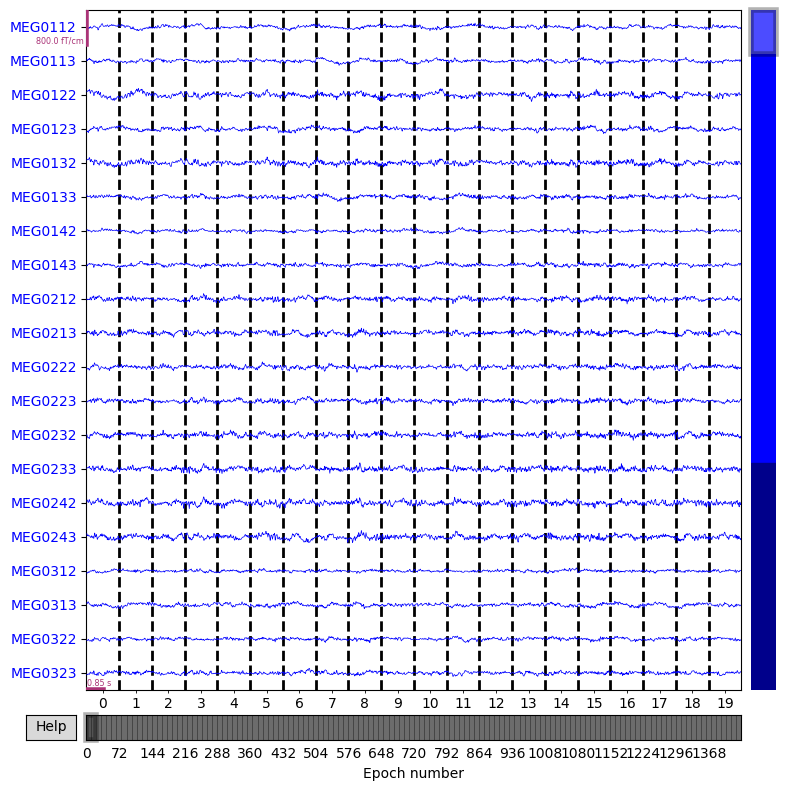

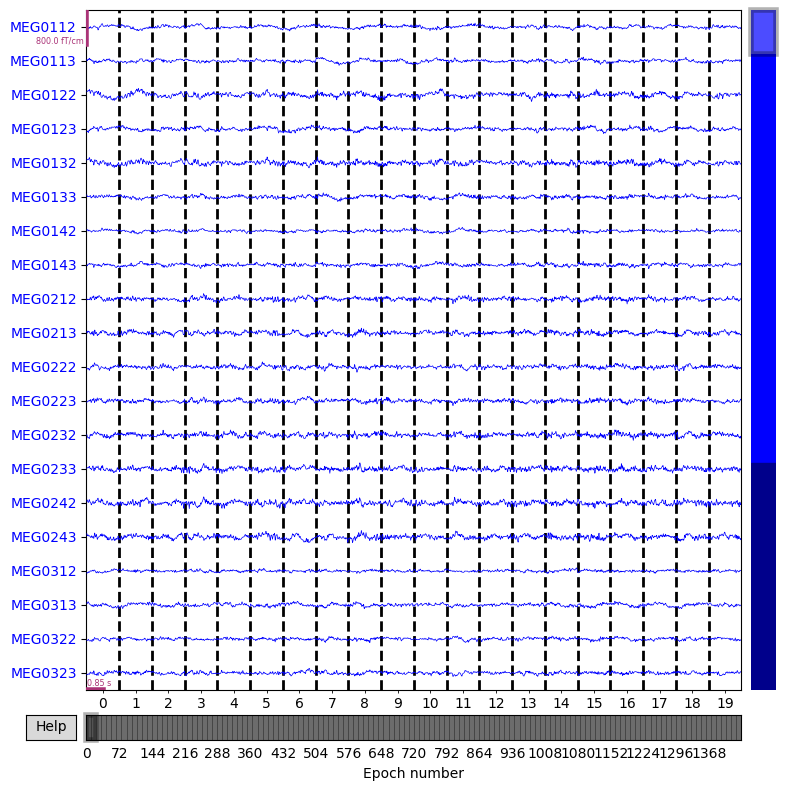

In [5]:
epochs.plot()

Projections have already been applied. Setting proj attribute to True.


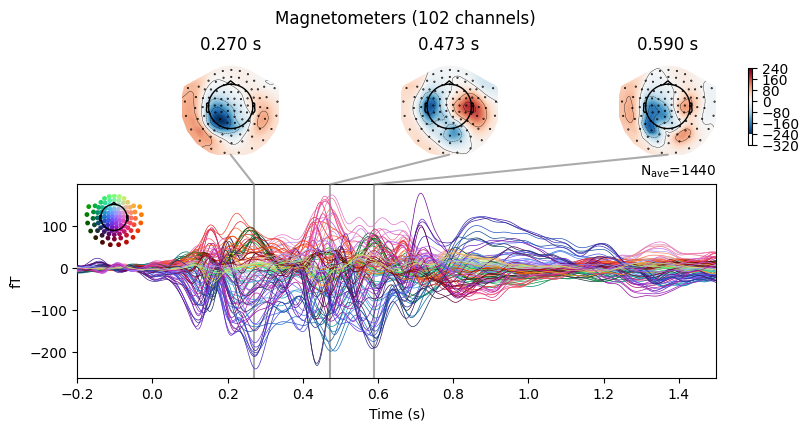

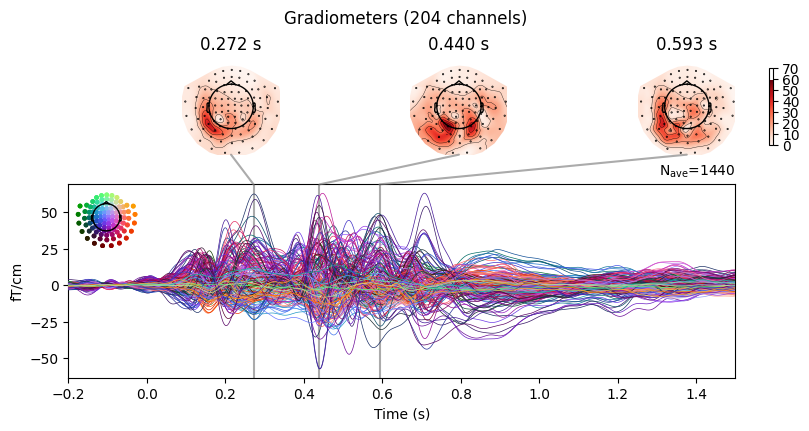

[<Figure size 800x420 with 6 Axes>, <Figure size 800x420 with 6 Axes>]

In [64]:
evoked = epochs.average()
evoked.plot_joint()
#evoked.plot_topomap(times=[0.1, 0.2, 0.3])

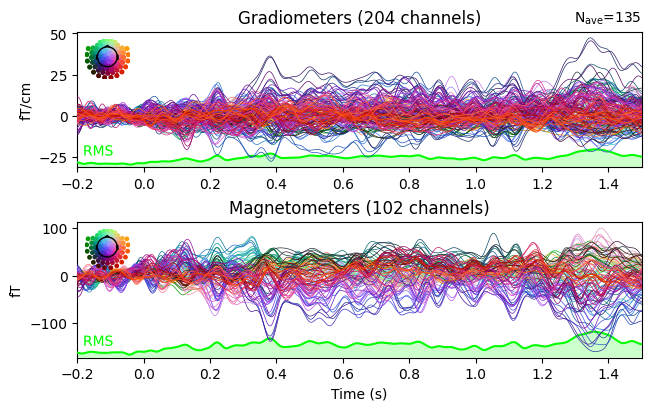

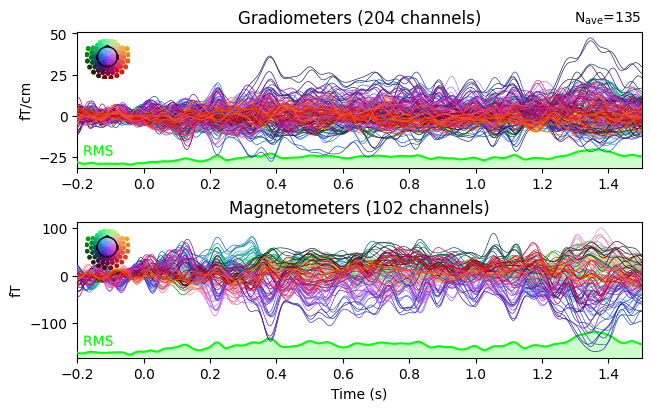

In [67]:
evoked2 = epochs['Stim/S2'].average()
evoked3 = epochs['Stim/S3'].average()
evokeds = [evoked2, evoked3]
#mne.viz.plot_compare_evokeds(evokeds, legend='upper right')
contrast = mne.combine_evoked([evoked2, evoked3], weights=[-1, 1])
contrast.plot(gfp=True)



Projections have already been applied. Setting proj attribute to True.


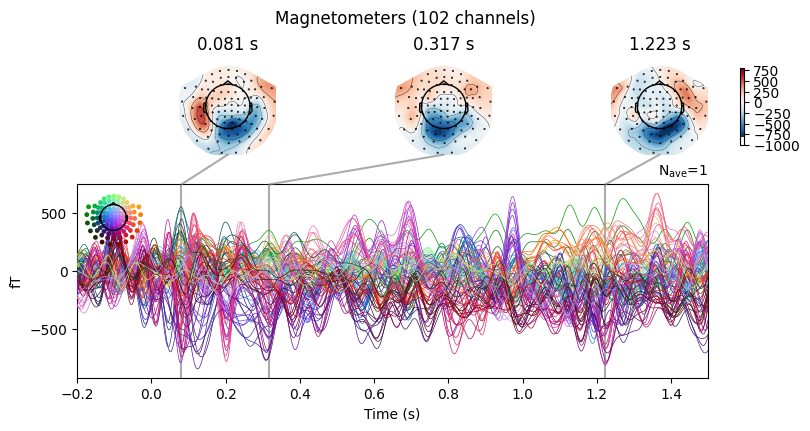

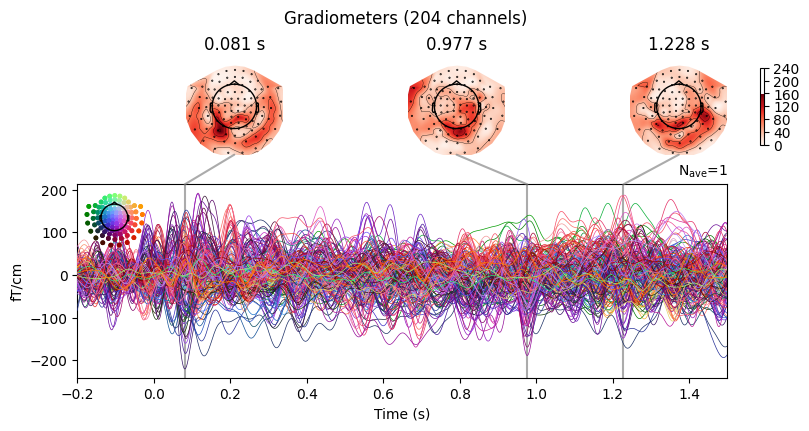

[<Figure size 800x420 with 6 Axes>, <Figure size 800x420 with 6 Axes>]

In [88]:
epochs[10].average().plot_joint()

In [ ]:
epochs.ch_names

    Using multitaper spectrum estimation with 7 DPSS windows
Averaging across epochs...


/Users/elodiehusson/Library/Python/3.8/lib/python/site-packages/mne/viz/utils.py:165: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  (fig or plt).show(**kwargs)


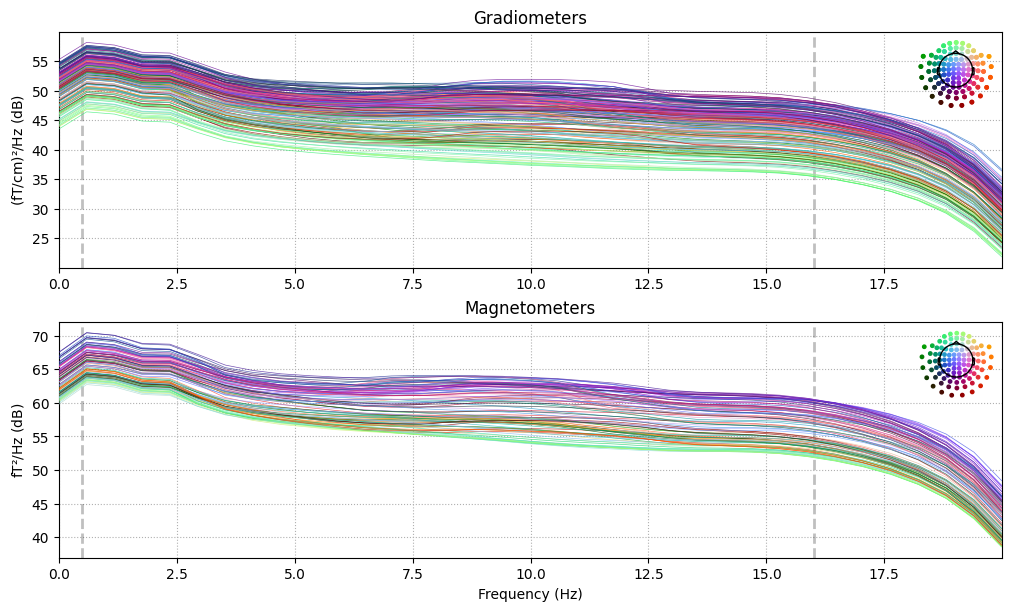

In [24]:
fig = epochs.compute_psd(tmax=0, fmax=20).plot()
fig

In [7]:
print(epochs)
epochs.plot()
epochs.event_id
epochs.metadata  # si tu en as

<EpochsFIF |  1440 events (all good), -0.2 – 1.5 s, baseline off, ~5.99 GB, data loaded, with metadata,
 'Stim/S1': 360
 'Stim/S2': 270
 'Stim/S3': 270
 'Stim/S4': 180
 'Stim/S5': 180
 'Stim/S6': 90
 'Stim/S7': 90>
Using matplotlib as 2D backend.


,index,event_name,BlockStart,Resp,RespProb,SeqStart,Stim/S1,Stim/S2,Stim/S3,Stim/S4,Stim/S5,Stim/S6,Stim/S7
0,0,Stim/S1,None,None,NaN,None,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Stim/S2,None,None,NaN,None,NaN,0.00,NaN,NaN,NaN,NaN,NaN
2,2,Stim/S3,None,None,NaN,None,NaN,NaN,0.000,1.418,NaN,NaN,NaN
3,3,Stim/S4,None,None,NaN,None,NaN,NaN,NaN,0.000,NaN,NaN,NaN
4,4,Stim/S5,None,None,NaN,None,NaN,NaN,NaN,NaN,0.0,1.476,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1435,1435,Stim/S1,None,None,NaN,None,0.0,1.41,NaN,NaN,NaN,NaN,NaN
1436,1436,Stim/S2,None,None,NaN,None,NaN,0.00,1.417,NaN,NaN,NaN,NaN
1437,1437,Stim/S3,None,None,NaN,None,NaN,NaN,0.000,1.427,NaN,NaN,NaN
1438,1438,Stim/S4,None,None,NaN,None,NaN,NaN,NaN,0.000,NaN,NaN,NaN


In [8]:
epochs["Stim"]

Number of events,1440
Events,Stim/S1: 360Stim/S2: 270Stim/S3: 270Stim/S4: 180Stim/S5: 180Stim/S6: 90Stim/S7: 90
Time range,-0.200 – 1.500 s
Baseline,off


### channels informations

In [20]:
mne.channel_indices_by_type(epochs.info)

{'eeg': [],
 'csd': [],
 'stim': [326],
 'eog': [0, 1],
 'ecg': [2],
 'emg': [],
 'misc': [321, 322, 323, 324, 325],
 'resp': [],
 'chpi': [],
 'exci': [3],
 'ias': [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 'syst': [327],
 'seeg': [],
 'dipole': [],
 'gof': [],
 'bio': [],
 'ecog': [],
 'dbs': [],
 'temperature': [],
 'gsr': [],
 'ref_meg': [],
 'mag': [15,
  18,
  21,
  24,
  27,
  30,
  33,
  36,
  39,
  42,
  45,
  48,
  51,
  54,
  57,
  60,
  63,
  66,
  69,
  72,
  75,
  78,
  81,
  84,
  87,
  90,
  93,
  96,
  99,
  102,
  105,
  108,
  111,
  114,
  117,
  120,
  123,
  126,
  129,
  132,
  135,
  138,
  141,
  144,
  147,
  150,
  153,
  156,
  159,
  162,
  165,
  168,
  171,
  174,
  177,
  180,
  183,
  186,
  189,
  192,
  195,
  198,
  201,
  204,
  207,
  210,
  213,
  216,
  219,
  222,
  225,
  228,
  231,
  234,
  237,
  240,
  243,
  246,
  249,
  252,
  255,
  258,
  261,
  264,
  267,
  270,
  273,
  276,
  279,
  282,
  285,
  288,
  291,
  294,
  297,
  300,
  30

## **Data plotting**

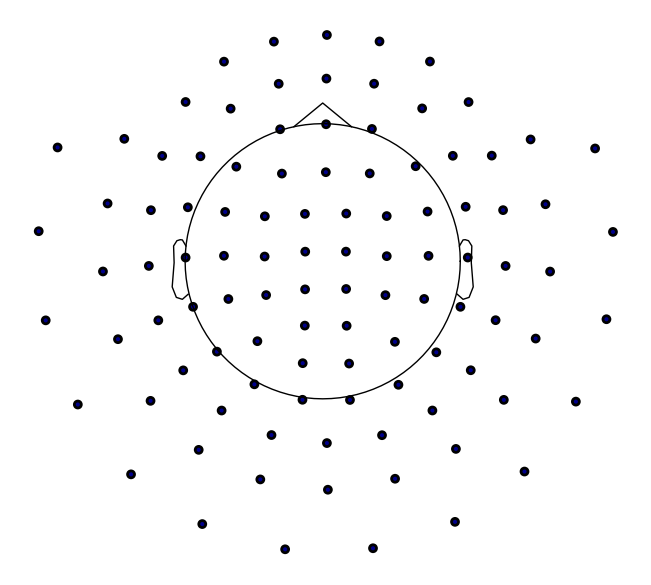

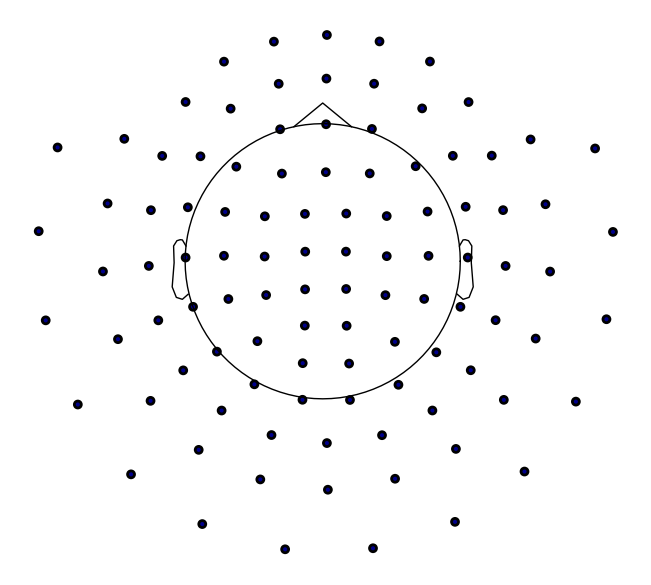

In [9]:
epochs.plot_sensors(ch_type="mag")

# **RAW FILE** detecting artefacts

In [9]:
ssp_projectors = raw.info["projs"]
raw.del_proj()

<Raw | run01.fif, 328 x 384000 (384.0 s), ~966.0 MiB, data loaded>

In [11]:
fig = epochs.compute_psd(tmax=np.inf, fmax=250).plot(
    average=True, amplitude=False, picks="data", exclude="bads"
)
# add some arrows at 60 Hz and its harmonics:
for ax in fig.axes[1:]:
    freqs = ax.lines[-1].get_xdata()
    psds = ax.lines[-1].get_ydata()
    for freq in (60, 120, 180, 240):
        idx = np.searchsorted(freqs, freq)
        ax.arrow(
            x=freqs[idx],
            y=psds[idx] + 18,
            dx=0,
            dy=-12,
            color="red",
            width=0.1,
            head_width=3,
            length_includes_head=True,
        )   

    Using multitaper spectrum estimation with 7 DPSS windows
Averaging across epochs...


/Users/elodiehusson/Library/Python/3.8/lib/python/site-packages/mne/viz/utils.py:165: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  (fig or plt).show(**kwargs)


In [13]:
events = mne.find_events(epochs)
print(events[:5])  # show the first 5

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

In [ ]:
event_dict = {
    "start of block": 255,
    "start of sequence": 128,
    "stim/S1": 129,
    "stim/S2": 130,
    "stim/S3": 131,
    "stim/S4": 132,
    "stim/S5": 133,
    "stim/S6": 134,
    "stim/S7": 135,
    "response presentation": 144,
    "response": 96,
}

In [17]:
fig = mne.viz.plot_events(events, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp)

/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_63514/3398464788.py:1: RuntimeWarning: More events than default colors available. You should pass a list of unique colors.
  fig = mne.viz.plot_events(events, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp)


In [54]:
sfreq = raw.info["sfreq"]
print(f"the sampling frequency (='sfreq') is {sfreq:.0f} Hz, meaning, the number of samples per second. Events are stored by number of sample. \nHaving the sampling frequency enables the events' extraction")

the sampling frequency (='sfreq') is 1000 Hz, meaning, the number of samples per second. Events are stored by number of sample. 
Having the sampling frequency enables the events' extraction


In [18]:
events_table = mne.find_events(epochs)


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

In [55]:
events_table = mne.find_events(raw, stim_channel='STI101')
events_table = pd.DataFrame(events_table, columns = ["sample_index", "zero", "event_code"])
events_table["event_times(s)"] = (events_table["sample_index"] - raw.first_samp) / sfreq
events_table["trigger_duration(ms)"] = events_table["event_times(s)"].diff()*1000
events_table

Finding events on: STI101
225 events found on stim channel STI101
Event IDs: [ 96 128 129 130 131 132 133 134 135 144 255]


,sample_index,zero,event_code,event_times(s),trigger_duration(ms)
0,544918,0,255,15.918,NaN
1,548011,0,128,19.011,3093.0
2,548680,0,129,19.680,669.0
3,549688,0,144,20.688,1008.0
4,555960,0,96,26.960,6272.0
...,...,...,...,...,...
220,889498,0,133,360.498,1501.0
221,890999,0,134,361.999,1501.0
222,892517,0,135,363.517,1518.0
223,893535,0,144,364.535,1018.0


In [21]:
events_table.to_csv(f"events_S0_B1.csv")

histograms of trigger distribution

In [26]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]==144])
plt.show()

In [27]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]!=255][events_table["event_code"]!=96][events_table["event_code"]!=144][events_table["event_code"]!=128][events_table["event_code"]!=129])
plt.show()

In [28]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]!=255][events_table["event_code"]!=96][events_table["event_code"]!=144])
plt.show()

In [29]:
for triggercode in events_table["event_code"].unique() : 
    plt.figure()
    x = events_table["trigger_duration(ms)"][1:,][events_table["event_code"]==triggercode]
    plt.hist(x)
    plt.title(f"histogramme des triggers pour trigger {triggercode}")
    plt.xlabel("temps (ms)")
    plt.show()

In [30]:
event_ids = sorted(events_table["event_code"].unique())

# créer un mapping position -> event id
y_pos = np.arange(len(event_ids))
mapping = dict(zip(event_ids, y_pos))

plt.figure(figsize=(12,6))
plt.grid(alpha = 0.4)

for event_id in event_ids:

    subset = events_table[events_table["event_code"] == event_id]

    plt.scatter(
        subset["event_times(s)"],
        [mapping[event_id]] * len(subset),
        label=f"id:{event_id}; N:{len(subset)}"
    )

plt.xlabel("Time (s)")
plt.ylabel("Event id")

# afficher les vrais labels
plt.yticks(y_pos, event_ids)
plt.show()

compter les triggers par bloc du coup

In [ ]:
Counter(events_table["event_code"])

Counter({128: 32,
         129: 32,
         144: 32,
         96: 32,
         130: 24,
         131: 24,
         132: 16,
         133: 16,
         134: 8,
         135: 8,
         255: 1})

In [34]:
raw.set_channel_types({"EOG061": "eog"})

ValueError: This channel name (EOG061) doesn't exist in info.

In [56]:
reject_criteria = dict(
    mag=4000e-15,  # 4000 fT
    grad=4000e-13,  # 4000 fT/cm
    # eog=250e-6,
)  # 250 µV

In [57]:
epochs = mne.Epochs(
    raw,
    events,
    event_id=event_dict,
    tmin=-0.2,
    tmax=0.5,
    reject=reject_criteria,
    preload=True,
)

Not setting metadata
225 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
Created an SSP operator (subspace dimension = 13)
13 projection items activated
Using data from preloaded Raw for 225 events and 701 original time points ...
    Rejecting  epoch based on MAG : ['MEG0141']
    Rejecting  epoch based on GRAD : ['MEG1122']
2 bad epochs dropped


In [58]:
epochs.plot_image(picks=["MEG1332"])

Not setting metadata
223 matching events found
No baseline correction applied
0 projection items activated


[<Figure size 1280x960 with 4 Axes>]

In [62]:
frequencies = np.arange(7, 30, 3)
power = epochs["stimulus/first"].compute_tfr(
    "morlet", n_cycles=2, return_itc=False, freqs=frequencies, decim=3, average=True
)
power.plot(["MEG0532"])

No baseline correction applied


[<Figure size 1280x960 with 2 Axes>]

In [68]:
first_evoked = epochs["stimulus/first"].average()
sec_evoked = epochs["stimulus/second"].average()
third_evoked = epochs["stimulus/third"].average()
fourth_evoked = epochs["stimulus/fourth"].average()
fifth_evoked = epochs["stimulus/fifth"].average()
sixth_evoked = epochs["stimulus/sixth"].average()
seventh_evoked = epochs["stimulus/seventh"].average()



mne.viz.plot_compare_evokeds(
    dict(first=first_evoked, second = sec_evoked, third = third_evoked, fourth=fourth_evoked, fifth = fifth_evoked, sixth = sixth_evoked, seventh = seventh_evoked),
    legend="upper left",
    show_sensors="upper right",
)

Multiple channel types selected, returning one figure per type.
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)


[<Figure size 1600x1200 with 2 Axes>, <Figure size 1600x1200 with 2 Axes>]

Projections have already been applied. Setting proj attribute to True.


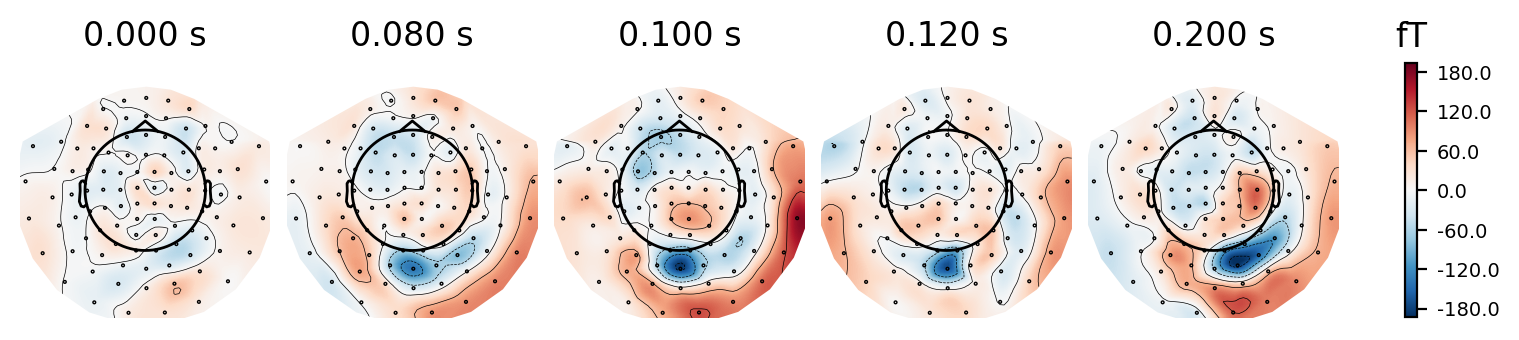

In [74]:
first_evoked.plot_joint(picks="mag")
first_evoked.plot_topomap(times=[0.0, 0.08, 0.1, 0.12, 0.2], ch_type="mag")

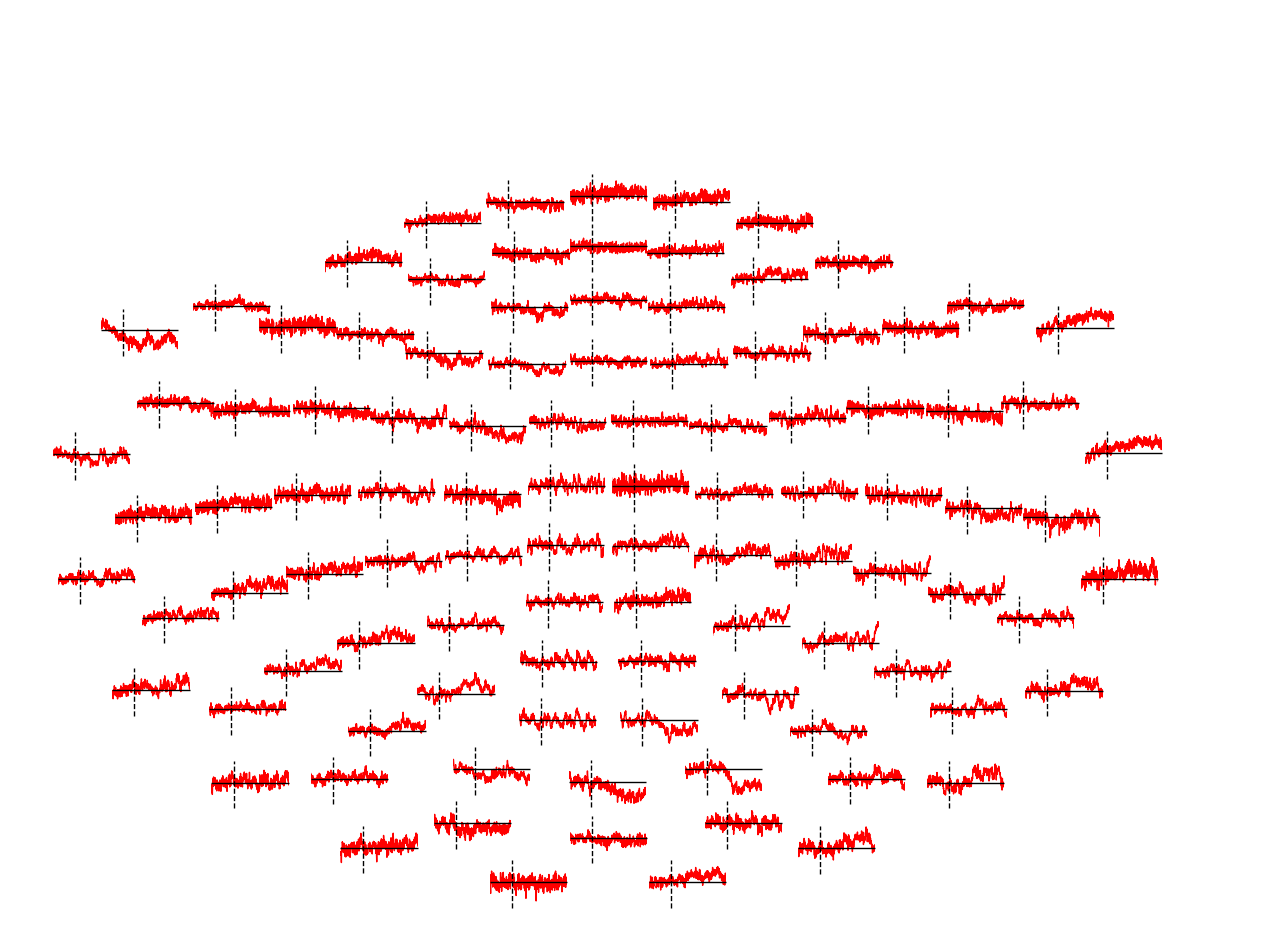

: 

In [ ]:
evoked_diff = mne.combine_evoked([first_evoked, sec_evoked], weights=[1, -1])
evoked_diff.pick(picks="mag").plot_topo(color="r", legend=False)